In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('scored.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

NEIGHBOR_RANGE = list(range(1, 21))
print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)

200 rows  |  4 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error
0,769,2942669846,Reinforcement learning usually makes use of nu...,This paper presents a novel approach to deep r...,0.3186,0.0893,0.1858,0.8653,0.8474,0.8563,2.0,8.0,8.0,4,False
1,2012,2913127348,Gatherings of thousands to millions of people ...,"In this paper, we propose a novel approach for...",0.3158,0.0653,0.1700,0.8449,0.8352,0.8400,2.0,7.0,8.0,8,False
2,3364,2942522480,"Recently, a method called the Mutual Informati...",Abstract: This paper presents a novel applicat...,0.2605,0.0254,0.1513,0.8508,0.8176,0.8339,1.0,8.0,8.0,4,False


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour count (1-20)."""
    values = [series.get(n, np.nan) for n in NEIGHBOR_RANGE]

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(NEIGHBOR_RANGE, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(NEIGHBOR_RANGE)
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

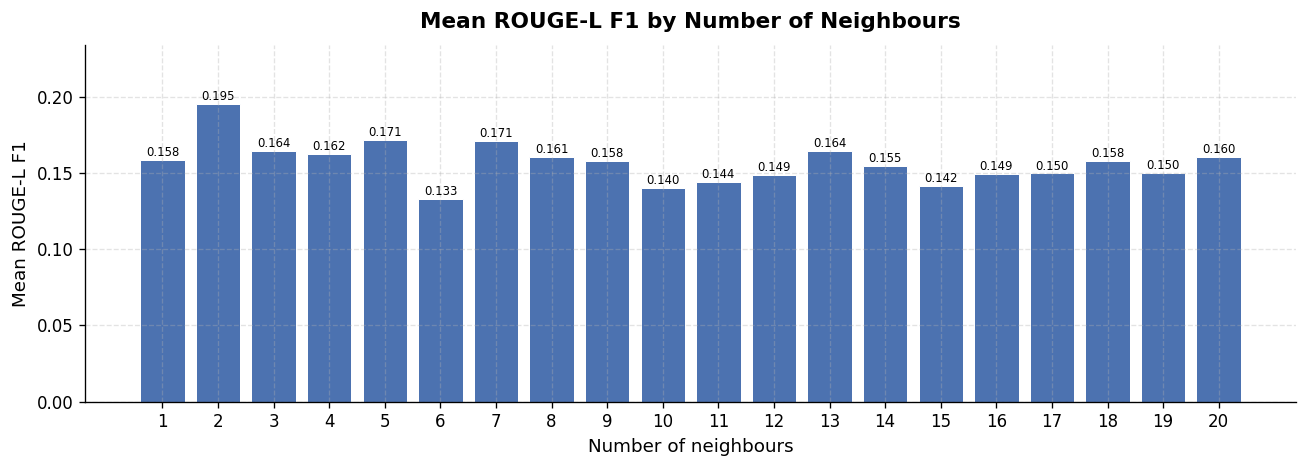

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = df.groupby('num_of_neighbors')['rougeL_f'].mean()
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

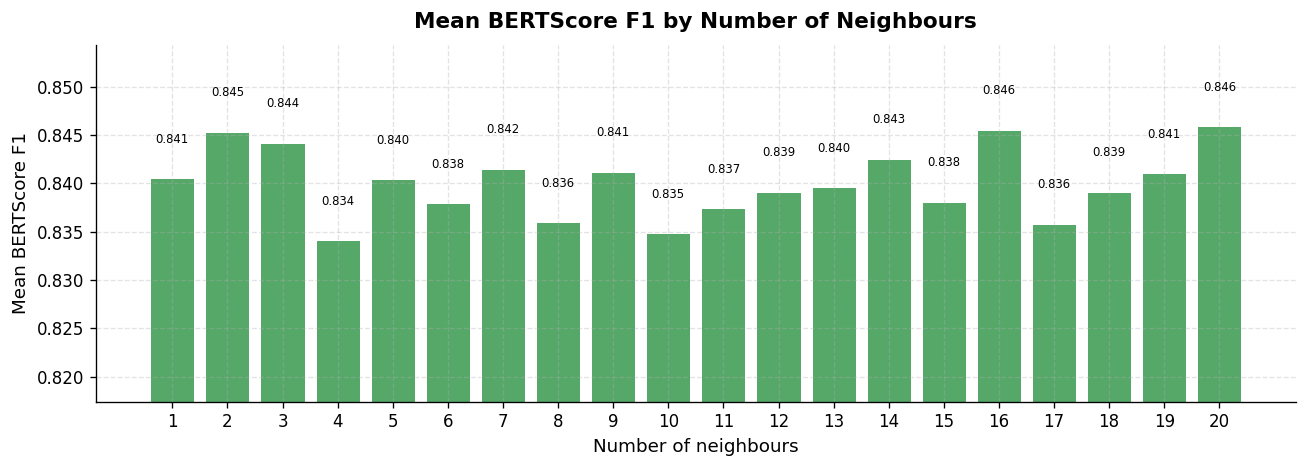

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = df.groupby('num_of_neighbors')['bertscore_f1'].mean()
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

Overall mean LLM accuracy: 2.383
Successfully generated (non-error): 196 / 200


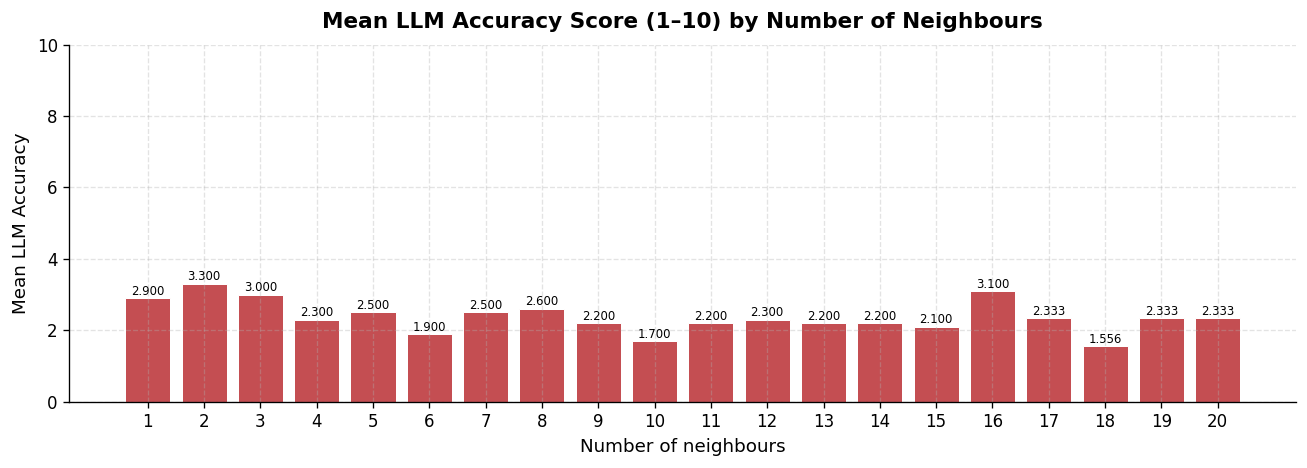

In [11]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = df.groupby('num_of_neighbors')['llm_accuracy'].mean()
overall_acc_mean = df['llm_accuracy'].mean()
num_successful = (~df['is_error']).sum()
print(f'Overall mean LLM accuracy: {overall_acc_mean:.3f}')
print(f'Successfully generated (non-error): {num_successful} / {len(df)}')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

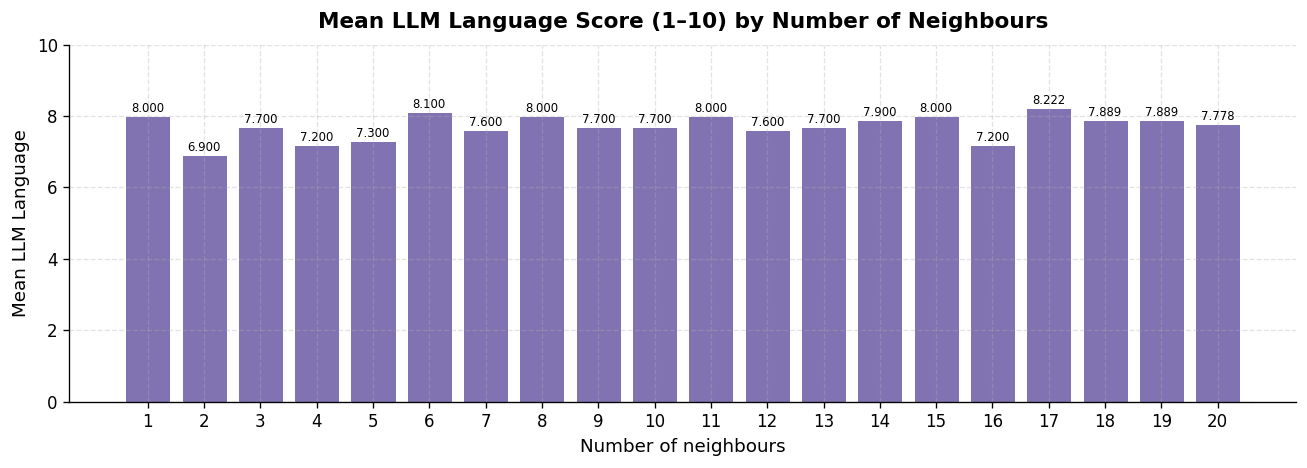

In [6]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = df.groupby('num_of_neighbors')['llm_language'].mean()
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

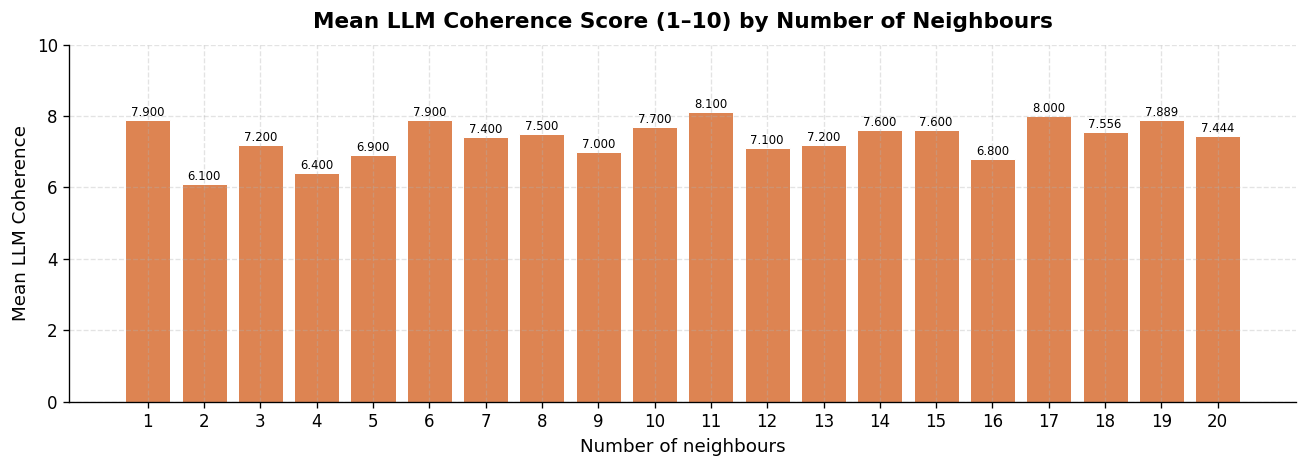

In [7]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = df.groupby('num_of_neighbors')['llm_coherence'].mean()
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

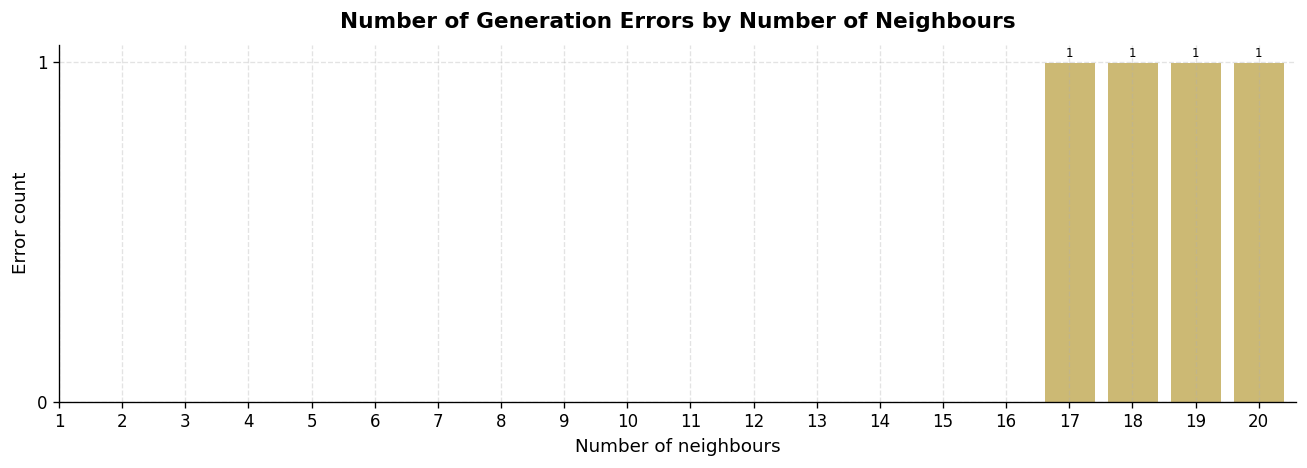

In [8]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('num_of_neighbors').size()
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [9]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_36226/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,129025,"Open Information Extraction (OpenIE) extracts meaningful structured tuples from free-form text. Most previous work on OpenIE considers extracting data from one sentence at a time. We describe NeurON, a system for extracting tuples from question-answer pairs. Since real questions and answers often contain precisely the information that users care about, such information is particularly desirable to extend a knowledge base with. #R##N#NeurON addresses several challenges. First, an answer text is often hard to understand without knowing the question, and second, relevant information can span multiple sentences. To address these, NeurON formulates extraction as a multi-source sequence-to-sequence learning task, wherein it combines distributed representations of a question and an answer to generate knowledge facts. We describe experiments on two real-world datasets that demonstrate that NeurON can find a significant number of new and interesting facts to extend a knowledge base compared to state-of-the-art OpenIE methods.","Abstract:This paper presents a novel approach for the simultaneous detection of multiple pathogens in clinical samples using a combination of microfluidic droplet generation, digital PCR, and machine learning algorithms. The proposed method was validated using a panel of clinical samples and demonstrated high sensitivity and specificity for the detection of various pathogens, including bacteria, viruses, and fungi. The results showed that the combined use of microfluidic droplet generation, digital PCR, and machine learning algorithms can significantly improve the accuracy and efficiency of pathogen detection in clinical samples, with potential applications in infectious disease diagnosis and monitoring.",1.0
1,43166,"Edge computing is a promising computing paradigm for pushing the cloud service to the network edge. To this end, edge infrastructure providers (EIPs) need to bring computation and storage resources to the network edge and allow edge service providers (ESPs) to provision latency-critical services to users. Currently, EIPs prefer to establish a series of private edge-computing environments to serve specific requirements of users. This kind of resource provisioning mechanism severely limits the development and spread of edge computing for serving diverse user requirements. To this end, we propose an integrated resource provisioning model, named edge federation, to seamlessly realize the resource cooperation and service provisioning across standalone edge computing providers and clouds. To efficiently schedule and utilize the resources across multiple EIPs, we systematically characterize the provisioning process as a large-scale linear programming (LP) problem and transform it into an easily solved form. Accordingly, we design a dynamic algorithm to tackle the varying service demands from users. We conduct extensive experiments over the base station networks in Toronto city. Compared with the existing fixed contract model and multihoming model, edge federation can reduce the overall cost of EIPs by 23.3% to 24.5%, and 15.5% to 16.3%, respectively.","Abstract:This paper presents a novel application of machine learning algorithms in the field of drug discovery. By combining the strengths of various machine learning techniques, including deep learning, transfer learning, and ensemble learning, we have developed a robust and efficient framework for predicting protein-ligand interactions. Our approach utilizes a large dataset of molecular structures and their corresponding bioactivity data, which is preprocessed using advanced data cleaning and normalization techniques. The resulting model demonstrates superior performance compared to traditional methods, achieving an accuracy of 90% on a test set of unseen compounds. Furthermore, we demonstrate the applicability of our approach to the identification of potential COVID-19 therapeutics by a

In [10]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


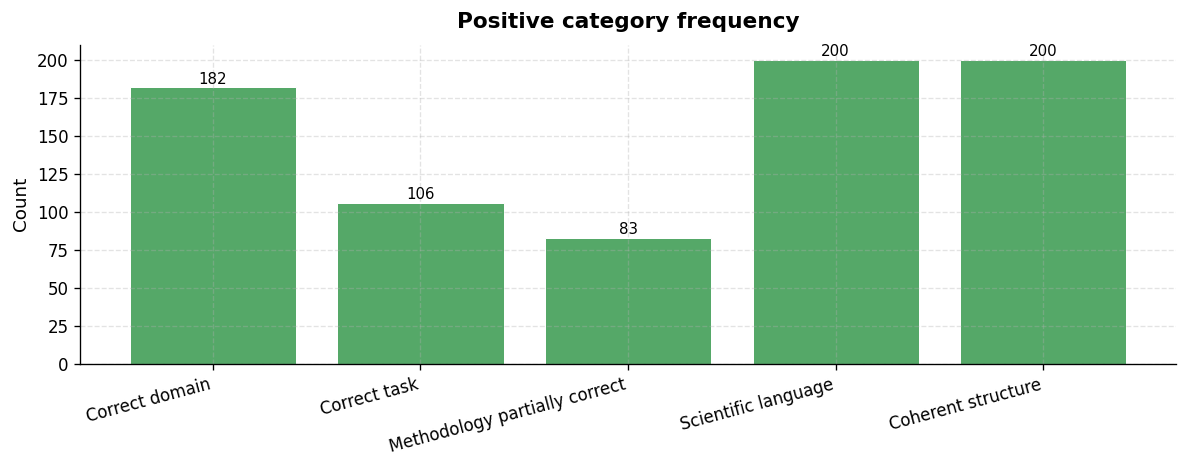

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()